# **TP2 : Manipulation d’histogramme - Egalisation**

**Elaboré par : Ayeb Farah - RT4/2**

#### **Étape 1 : Importation des bibliothèques**

In [42]:
import cv2 as cv
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from skimage.filters import rank
from skimage.morphology import disk
from skimage import data
from skimage.util import img_as_ubyte
from skimage import exposure
import skimage.morphology as morp
from skimage.io import imsave, imread
import warnings
warnings.filterwarnings('ignore')

#### **Étape 2 : Lecture de l'image `vallee.png`**

In [6]:
path = "vallee.png"
img = cv.imread(path, cv.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Image introuvable : {path}")

print(f"Image chargée — dimensions : {img.shape}, dtype : {img.dtype}")

Image chargée — dimensions : (295, 443), dtype : uint8


#### **Étape 3 : Affichage de l'image originale**

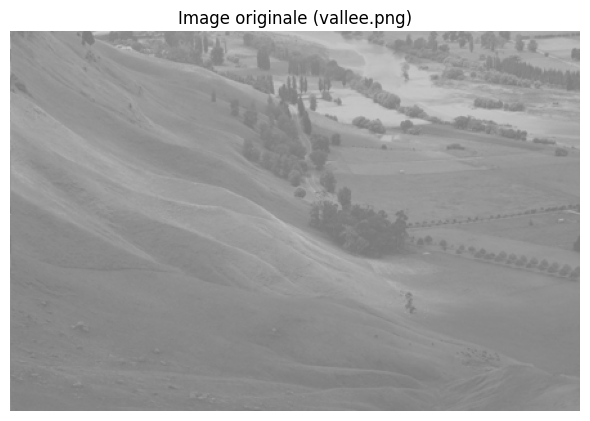

In [7]:
plt.figure(figsize=(6, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Image originale (vallee.png)")
plt.axis("off")
plt.tight_layout()
plt.show()

#### **Étape 4 : Histogramme et CDF de l'image originale**

**cdf :** Cumulative Distribution Function of an image

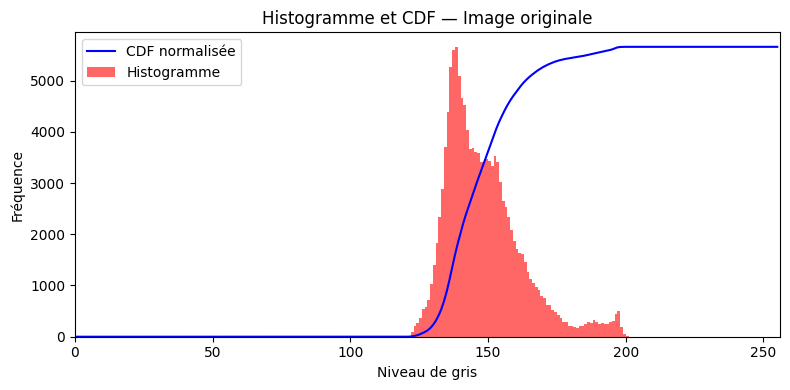

In [8]:
hist, bins = np.histogram(img.flatten(), 256, [0, 256])
cdf = hist.cumsum()                                         # CDF brute
cdf_normalized = cdf * float(hist.max()) / cdf.max()        # CDF normalisée pour superposition

plt.figure(figsize=(8, 4))
plt.plot(cdf_normalized, color='b', label='CDF normalisée')
plt.hist(img.flatten(), 256, [0, 256], color='r', alpha=0.6, label='Histogramme')
plt.xlim([0, 256])
plt.xlabel("Niveau de gris")
plt.ylabel("Fréquence")
plt.title("Histogramme et CDF — Image originale")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Observation:**

L'histogramme de l'image originale "vallee.png" montre une concentration de pixels sur une plage étroite de niveaux de gris, généralement dans les tons moyens à clairs, ce qui indique un contraste faible. La CDF normalisée monte rapidement au début, ce qui confirme que la majorité des pixels sont dans les niveaux de gris bas confirmant sa distribution non uniforme.

#### **Étape 6 : Égalisation d'histogramme globale (HE) avec OpenCV**

In [9]:
equ = cv.equalizeHist(img)
print("Égalisation globale appliquée.")

Égalisation globale appliquée.


#### **Étape 7 – Affichage de l'image égalisée et de son histogramme**

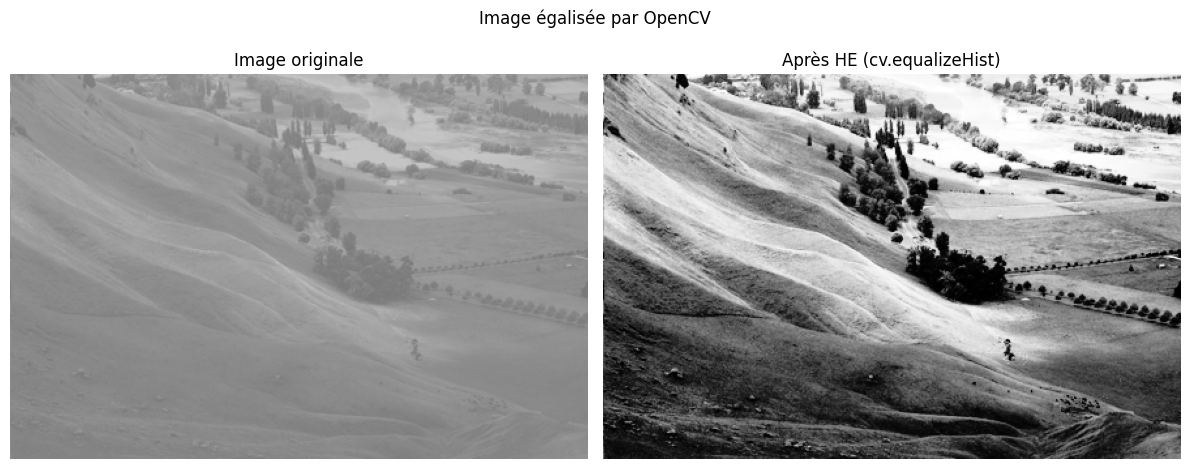

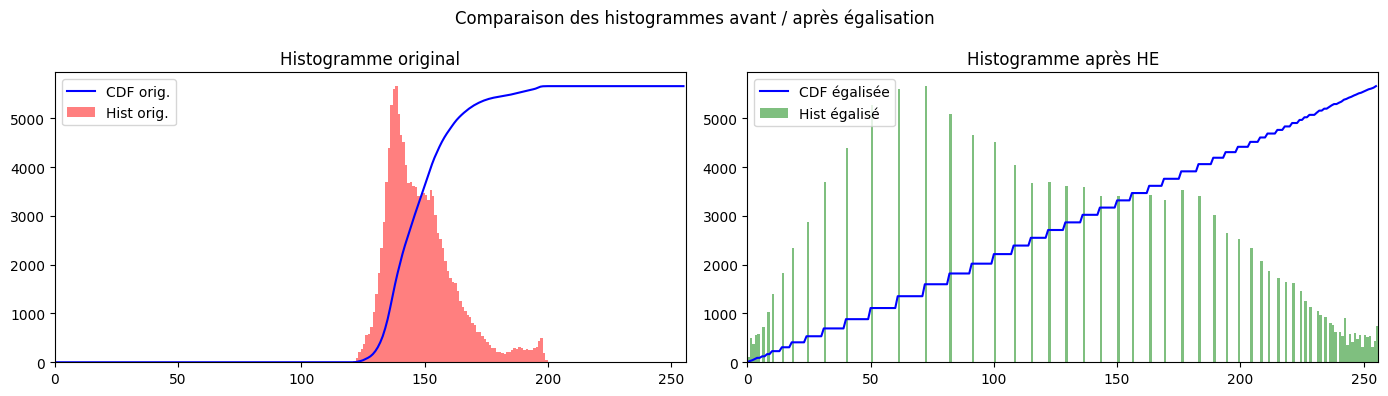

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Image originale")
axes[0].axis("off")
axes[1].imshow(equ, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Après HE (cv.equalizeHist)")
axes[1].axis("off")
plt.suptitle("Image égalisée par OpenCV")
plt.tight_layout()
plt.show()

# --- Histogramme + CDF de l'image égalisée ---
hist_equ, _ = np.histogram(equ.flatten(), 256, [0, 256])
cdf_equ = hist_equ.cumsum()
cdf_equ_norm = cdf_equ * float(hist_equ.max()) / cdf_equ.max()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(cdf_normalized, color='b', label='CDF orig.')
axes[0].hist(img.flatten(), 256, [0, 256], color='r', alpha=0.5, label='Hist orig.')
axes[0].set_xlim([0, 256])
axes[0].set_title("Histogramme original")
axes[0].legend(loc='upper left')

axes[1].plot(cdf_equ_norm, color='b', label='CDF égalisée')
axes[1].hist(equ.flatten(), 256, [0, 256], color='g', alpha=0.5, label='Hist égalisé')
axes[1].set_xlim([0, 256])
axes[1].set_title("Histogramme après HE")
axes[1].legend(loc='upper left')

plt.suptitle("Comparaison des histogrammes avant / après égalisation")
plt.tight_layout()
plt.show()

**Observation:**

L'image égalisée par OpenCV présente un contraste amélioré, avec une distribution plus uniforme des niveaux de gris. L'histogramme de l'image égalisée montre une répartition plus équilibrée des pixels à travers les différentes intensités, tandis que la CDF normalisée est plus linéaire, indiquant une meilleure utilisation de la gamme dynamique disponible.

### **Égalisation adaptative (AHE)**

AHE (Adaptive Histogram Equalization) est une extension de l'égalisation classique (HE) qui opère localement plutôt que globalement sur toute l'image.

**Principe de base :**

Avec HE classique, on calcule un seul histogramme pour toute l'image et on applique une transformation uniforme à chaque pixel. Le problème : si une zone sombre et une zone claire coexistent dans l'image, la transformation globale ne sera optimale pour aucune des deux.
AHE résout cela en divisant l'image en une grille de régions (tuiles M×N), puis en calculant un histogramme indépendant pour chaque tuile et en appliquant une transformation locale à chaque pixel en fonction de sa région.

#### **Étape 8 – AHE avec scikit-image**

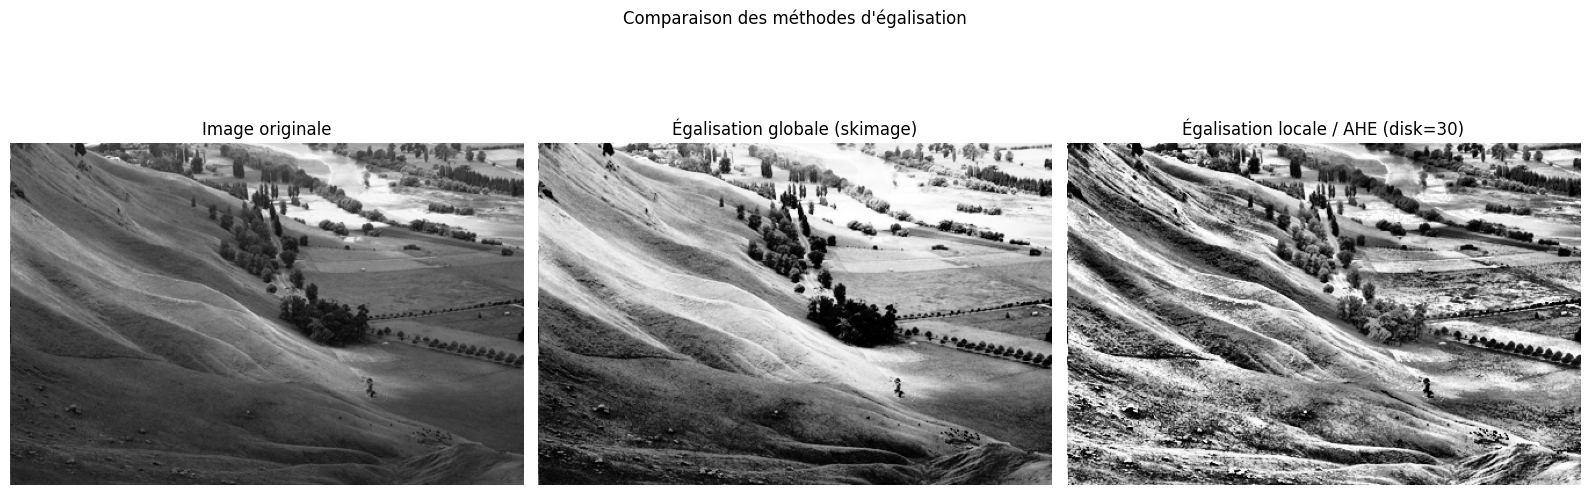

In [14]:
# Lecture de l'image
img_sk = img_as_ubyte(imread(path, as_gray=True))

# Égalisation globale (skimage)
img_global = exposure.equalize_hist(img_sk)

# Égalisation locale avec noyau disque de rayon 30
kernel = morp.disk(30)
img_local = rank.equalize(img_sk, footprint=kernel)

plt.rcParams['figure.figsize'] = [16, 6]
fig, (ax_img, ax_global, ax_local) = plt.subplots(1, 3)

ax_img.imshow(img_sk, cmap=plt.cm.gray)
ax_img.set_title('Image originale')
ax_img.axis('off')

ax_global.imshow(img_global, cmap=plt.cm.gray)
ax_global.set_title('Égalisation globale (skimage)')
ax_global.axis('off')

ax_local.imshow(img_local, cmap=plt.cm.gray)
ax_local.set_title('Égalisation locale / AHE (disk=30)')
ax_local.axis('off')

plt.suptitle("Comparaison des méthodes d'égalisation")
plt.tight_layout()
plt.show()

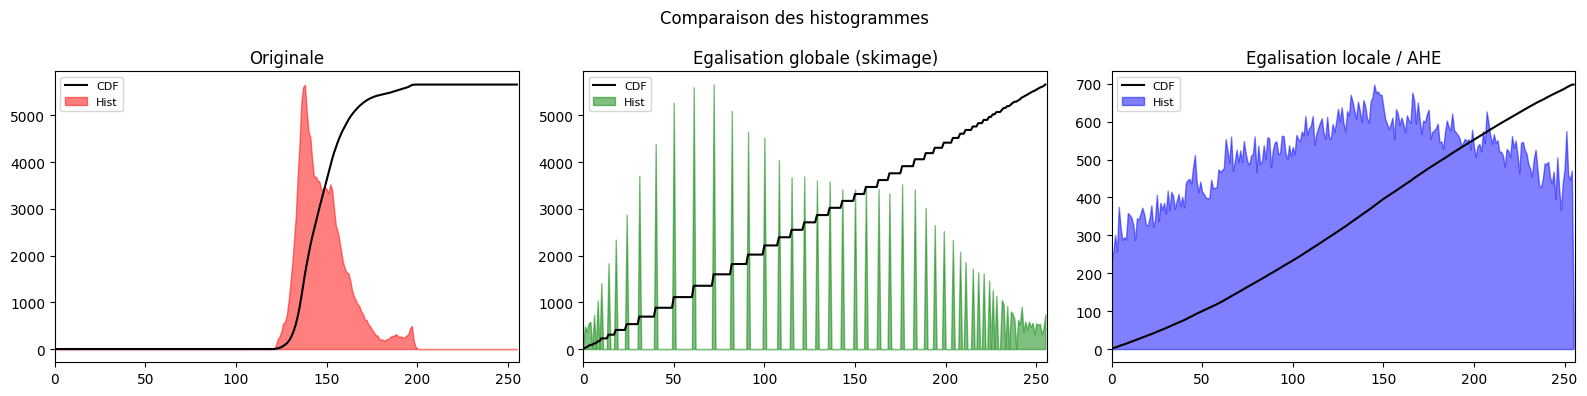

In [15]:
# Conversion img_global en uint8 pour calculer l'histogramme
img_global_u8 = img_as_ubyte(img_global)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, image, title, color in zip(
        axes,
        [img_sk, img_global_u8, img_local],
        ['Originale', 'Egalisation globale (skimage)', 'Egalisation locale / AHE'],
        ['red', 'green', 'blue']
):
    h, _ = np.histogram(image.flatten(), 256, [0, 256])
    cdf_i = h.cumsum()
    cdf_i_norm = cdf_i * float(h.max()) / cdf_i.max()
    ax.plot(cdf_i_norm, color='black', linewidth=1.5, label='CDF')
    ax.fill_between(range(256), h, alpha=0.5, color=color, label='Hist')
    ax.set_xlim([0, 256])
    ax.set_title(title)
    ax.legend(loc='upper left', fontsize=8)

plt.suptitle("Comparaison des histogrammes")
plt.tight_layout()
plt.show()

**Observation:**

L'égalisation locale (AHE) avec un noyau de disque de rayon 30 améliore significativement le contraste dans les zones sombres et claires de l'image, contrairement à l'égalisation globale qui peut laisser certaines zones sous-exposées ou surexposées. L'histogramme de l'image égalisée localement montre une distribution plus équilibrée des niveaux de gris, tandis que la CDF est plus linéaire, indiquant une meilleure utilisation de la gamme dynamique.

#### **Étape 9 – CLAHE avec OpenCV**

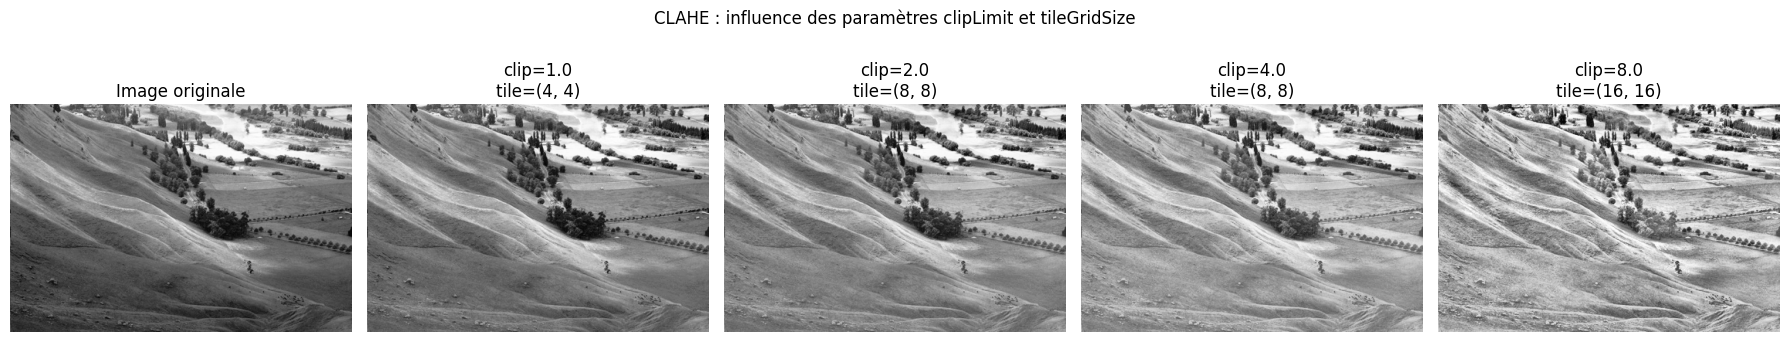

In [17]:
img_color = cv.imread(path)
grayimg = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

# --- Paramètres à tester ---
configs = [
    {"clipLimit": 1.0, "tileGridSize": (4, 4)},
    {"clipLimit": 2.0, "tileGridSize": (8, 8)},   # valeur de référence
    {"clipLimit": 4.0, "tileGridSize": (8, 8)},
    {"clipLimit": 8.0, "tileGridSize": (16, 16)},
]

fig, axes = plt.subplots(1, len(configs) + 1, figsize=(18, 4))

axes[0].imshow(grayimg, cmap="Greys_r")
axes[0].set_title("Image originale")
axes[0].axis("off")

for ax, cfg in zip(axes[1:], configs):
    clahe = cv.createCLAHE(clipLimit=cfg["clipLimit"], tileGridSize=cfg["tileGridSize"])
    cl = clahe.apply(grayimg)
    ax.imshow(cl, cmap="Greys_r")
    ax.set_title(f"clip={cfg['clipLimit']}\ntile={cfg['tileGridSize']}")
    ax.axis("off")

plt.suptitle("CLAHE : influence des paramètres clipLimit et tileGridSize")
plt.tight_layout()
plt.show()

**Observation:**

L'augmentation du `clipLimit` dans CLAHE permet de limiter davantage le contraste local, ce qui peut éviter la sur-amplification du bruit dans les zones homogènes. Cependant, un `clipLimit` trop élevé peut réduire l'efficacité de l'amélioration du contraste. De même, une `tileGridSize` plus grande peut conduire à une égalisation plus globale, tandis qu'une taille plus petite permet une égalisation plus locale, mais peut introduire du bruit si elle est trop petite. Le choix optimal dépend de l'image et des objectifs de traitement.

En effet , un `clipLimit` faible (1) produit une amélioration modérée et préserve la luminosité naturelle. Augmenter la valeur (4–8) amplifie le contraste local mais peut introduire du bruit ou des artefacts visuels. Une taille de tuile plus petite améliore les détails locaux mais peut créer des discontinuités aux bords si le paramètre de clip est élevé.

## **Reproduction des méthodes de l'article (sur l'image de la rétine)**

Les quatre méthodes testées sont :
- **HE** : Histogram Equalization
- **CHE** : Cumulative Histogram Equalization
- **QDHE** : Quadrant Dynamic Histogram Equalization
- **CLAHE** : Contrast Limited Adaptive Histogram Equalization

#### **I. Chargement des images de la rétine**

Rétine 1 chargée, ses dimensions : (512, 512)
Rétine 2 chargée, ses dimensions : (512, 512)
Rétine 3 chargée, ses dimensions : (512, 512)
Rétine 4 chargée, ses dimensions : (512, 512)


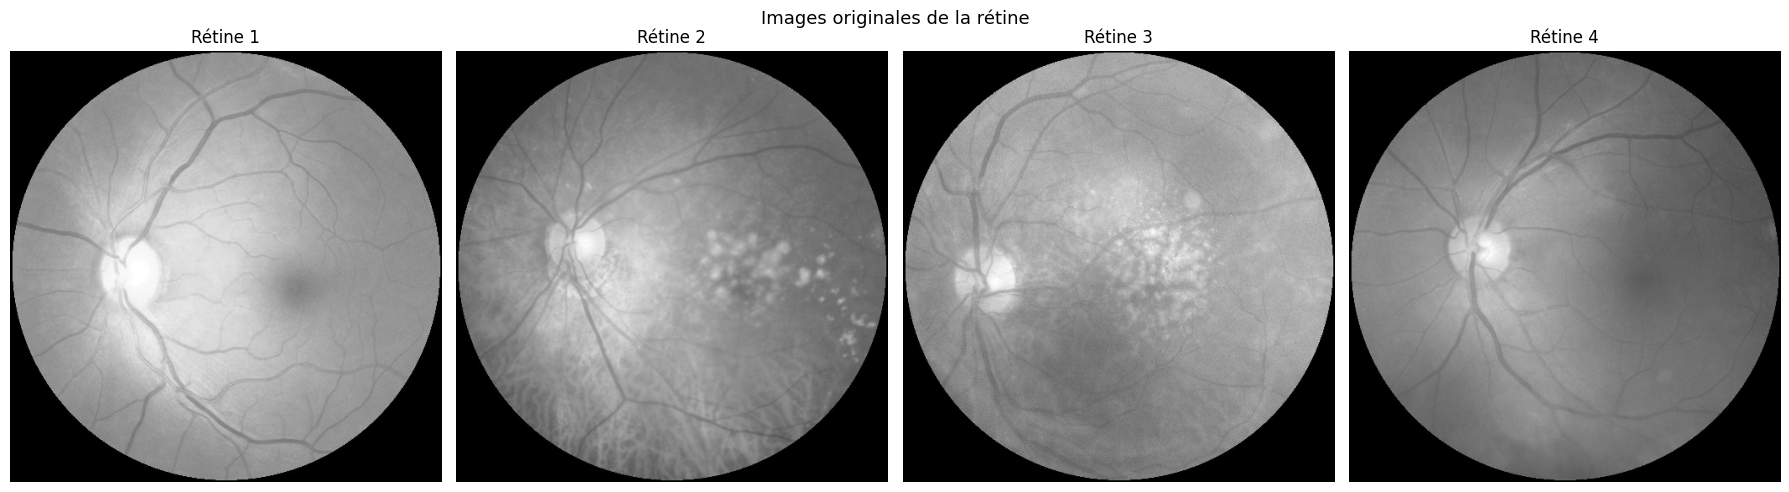

In [19]:
retina_paths = [
    "416_left.jpg",
    "1820_left.jpg",
    "1889_left.jpg",
    "2427_left.jpg"
]
retina_names = ["Rétine 1", "Rétine 2", "Rétine 3", "Rétine 4"]
retinas = []
for path, name in zip(retina_paths, retina_names):
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Image introuvable : {path}")
    retinas.append(img)
    print(f"{name} chargée, ses dimensions : {img.shape}")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, img, name in zip(axes, retinas, retina_names):
    ax.imshow(img, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.suptitle("Images originales de la rétine", fontsize=13)
plt.tight_layout()
plt.show()

#### **II. Application des méthodes d'égalisation sur les images de la rétine**


**1. HE :** Egalisation d'histogramme globale standard, appliquée à toute les images.

In [20]:
def apply_HE(img):
    return cv.equalizeHist(img)

**2. CHE :** Egalisation d'histogramme cumulative, qui utilise la CDF pour transformer les pixels en utilisant l'équation 7 de l'article.

In [21]:
def apply_CHE(img):
    L = 256
    M, N = img.shape
    hist, _ = np.histogram(img.flatten(), L, [0, L])
    cdf = hist.cumsum()
    cdf_min = cdf[cdf > 0].min()
    denom = M * N - cdf_min
    lut = np.round((cdf - cdf_min) / denom * (L - 1)).astype(np.uint8)
    lut = np.clip(lut, 0, 255)
    return lut[img]

**3. QDHE :** Quadrant Dynamic Histogram Equalization, qui divise l'histogramme en quatre sous-histogrammes basés sur les quartiles, applique un clipping et une allocation dynamique des plages, puis effectue une égalisation indépendante pour chaque sous-histogramme.

In [35]:
def apply_QDHE(img):
    assert img.ndim == 2
    L = 256
    M, N = img.shape
    total = M * N
    hist, _ = np.histogram(img.flatten(), L, [0, L])

    # Partition par quartiles
    cumsum = hist.cumsum().astype(np.float64)
    targets = [total * q for q in (0.25, 0.50, 0.75)]
    separators = [0]
    for t in targets:
        idx = int(np.searchsorted(cumsum, t))
        separators.append(min(idx, L - 1))
    separators.append(L - 1)

    # Clipping
    Tc = float(img.mean())
    hist_clipped = np.minimum(hist.astype(float), Tc)

    # Allocation des plages
    spans = [max(separators[i+1] - separators[i], 1) for i in range(4)]
    total_span = sum(spans)
    ranges_alloc = [max(int(round((L-1) * s / total_span)), 1) for s in spans]
    ranges_alloc[-1] = (L - 1) - sum(ranges_alloc[:-1])  # ajustement final

    out_starts = [sum(ranges_alloc[:i]) for i in range(4)]
    out_ends   = [out_starts[i] + ranges_alloc[i] for i in range(4)]

    # LUT : HE indépendante par sous-histogramme
    lut = np.zeros(L, dtype=np.uint8)
    for i in range(4):
        lo = separators[i]
        hi = separators[i + 1]
        sub = hist_clipped[lo: hi + 1]
        sub_cdf = sub.cumsum()
        cdf_max = sub_cdf[-1]
        i_start, i_end = out_starts[i], out_ends[i]

        for k in range(len(sub)):
            if cdf_max > 0:
                val = int(round((i_end - i_start) * sub_cdf[k] / cdf_max + i_start))
            else:
                val = i_start
            lut[lo + k] = np.clip(val, 0, 255)

    return lut[img]

**4. CLAHE :** Egalisation d'histogramme adaptative limitée par contraste, qui applique une égalisation locale avec un clipping pour limiter l'amplification du contraste dans les zones homogènes.

In [24]:
def apply_CLAHE(img, clipLimit=2.0, tileGridSize=(8, 8)):
    clahe = cv.createCLAHE(clipLimit=clipLimit, tileGridSize=tileGridSize)
    return clahe.apply(img)

**5. Affichage des résultats pour les 4 méthodes sur les 4 images de la rétine**

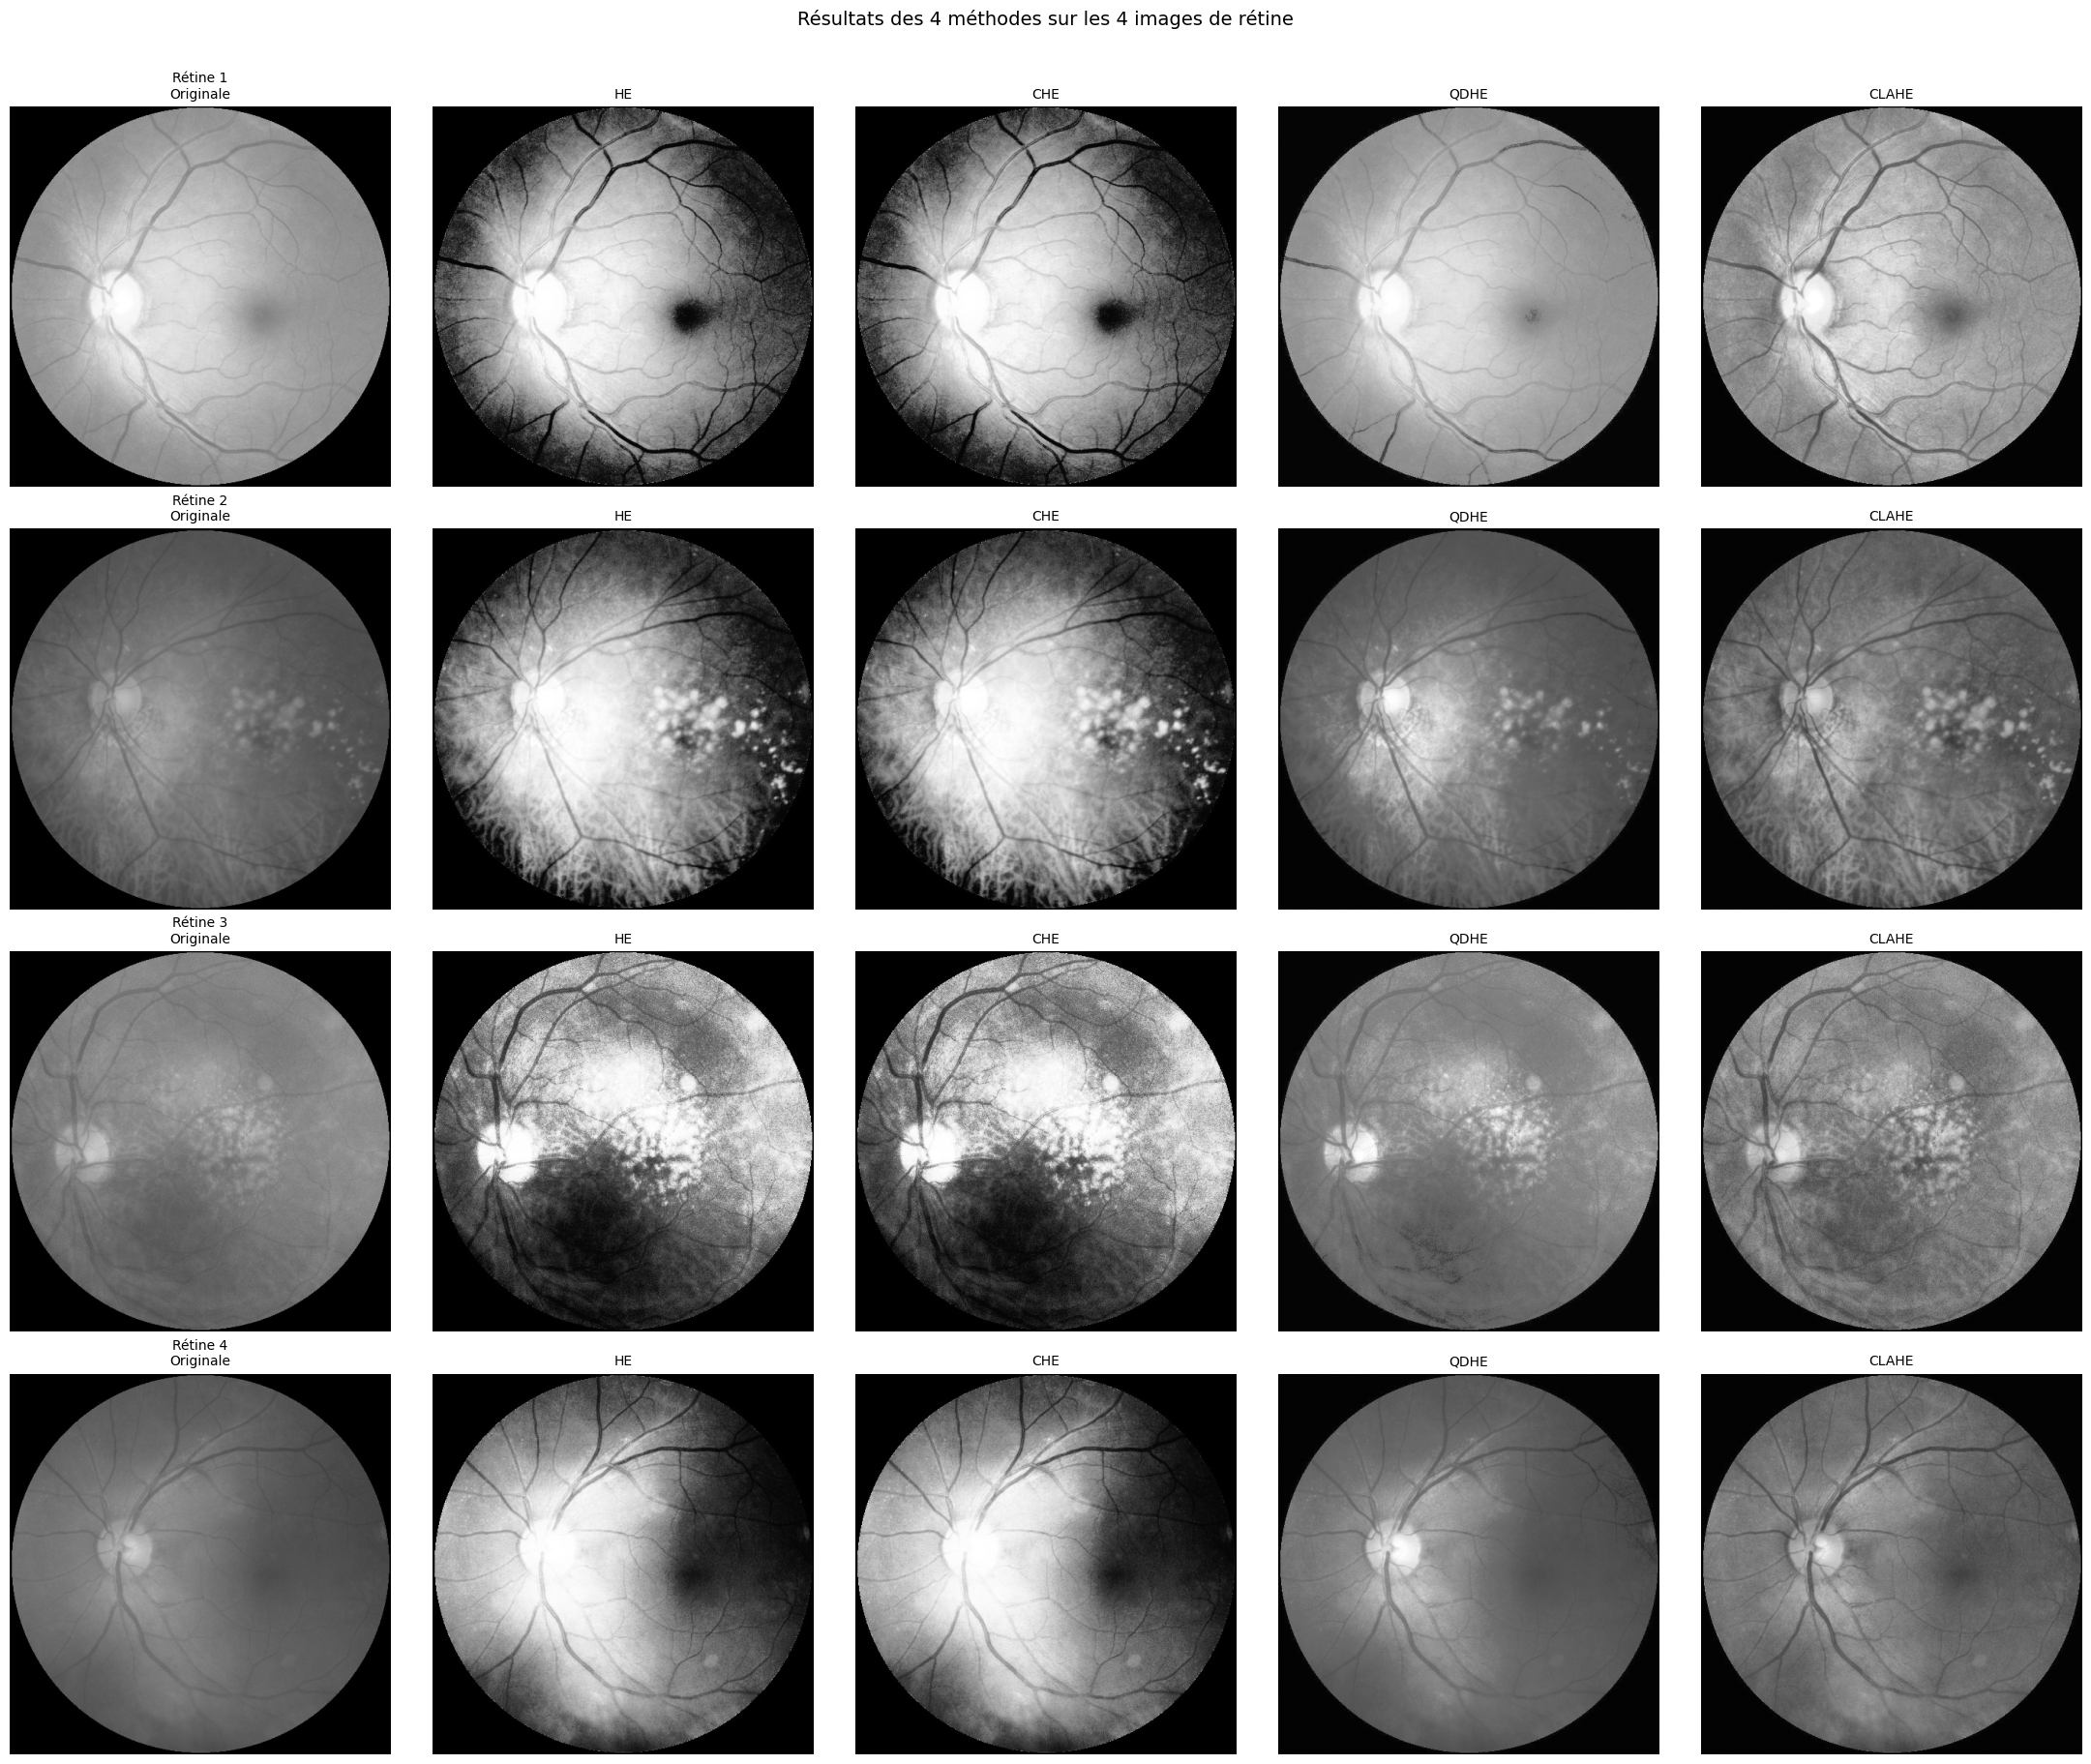

In [36]:
method_names = ["HE", "CHE", "QDHE", "CLAHE"]
method_funcs = [apply_HE, apply_CHE, apply_QDHE, apply_CLAHE]

# Dictionnaire : results[i] = {"HE": img, "CHE": img, ...}
results_imgs = []
for img in retinas:
    results_imgs.append({name: func(img) for name, func in zip(method_names, method_funcs)})

# Affichage : une ligne par image de rétine
fig, axes = plt.subplots(4, 5, figsize=(22, 18))

for row, (img, res, rname) in enumerate(zip(retinas, results_imgs, retina_names)):
    # Colonne 0 : originale
    axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"{rname}\nOriginale", fontsize=10)
    axes[row, 0].axis("off")
    # Colonnes 1-4 : méthodes
    for col, mname in enumerate(method_names, start=1):
        axes[row, col].imshow(res[mname], cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(mname, fontsize=10)
        axes[row, col].axis("off")

plt.suptitle("Résultats des 4 méthodes sur les 4 images de rétine", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Observation:**

Les différentes méthodes d'égalisation d'histogramme produisent des résultats variés sur les images de la rétine. HE améliore le contraste global mais peut laisser certaines zones sous-exposées ou surexposées. CHE offre une transformation basée sur la CDF, ce qui peut améliorer le contraste de manière plus uniforme. QDHE divise l'histogramme en quadrants, ce qui permet une égalisation plus ciblée, mais peut introduire des artefacts si les séparateurs ne sont pas bien choisis. CLAHE améliore localement le contraste tout en limitant l'amplification du bruit, ce qui est particulièrement bénéfique pour les images de la rétine où les détails fins sont importants.

#### **III. Analyse des histogrammes des images de la rétine avant et après application des méthodes d'égalisation**

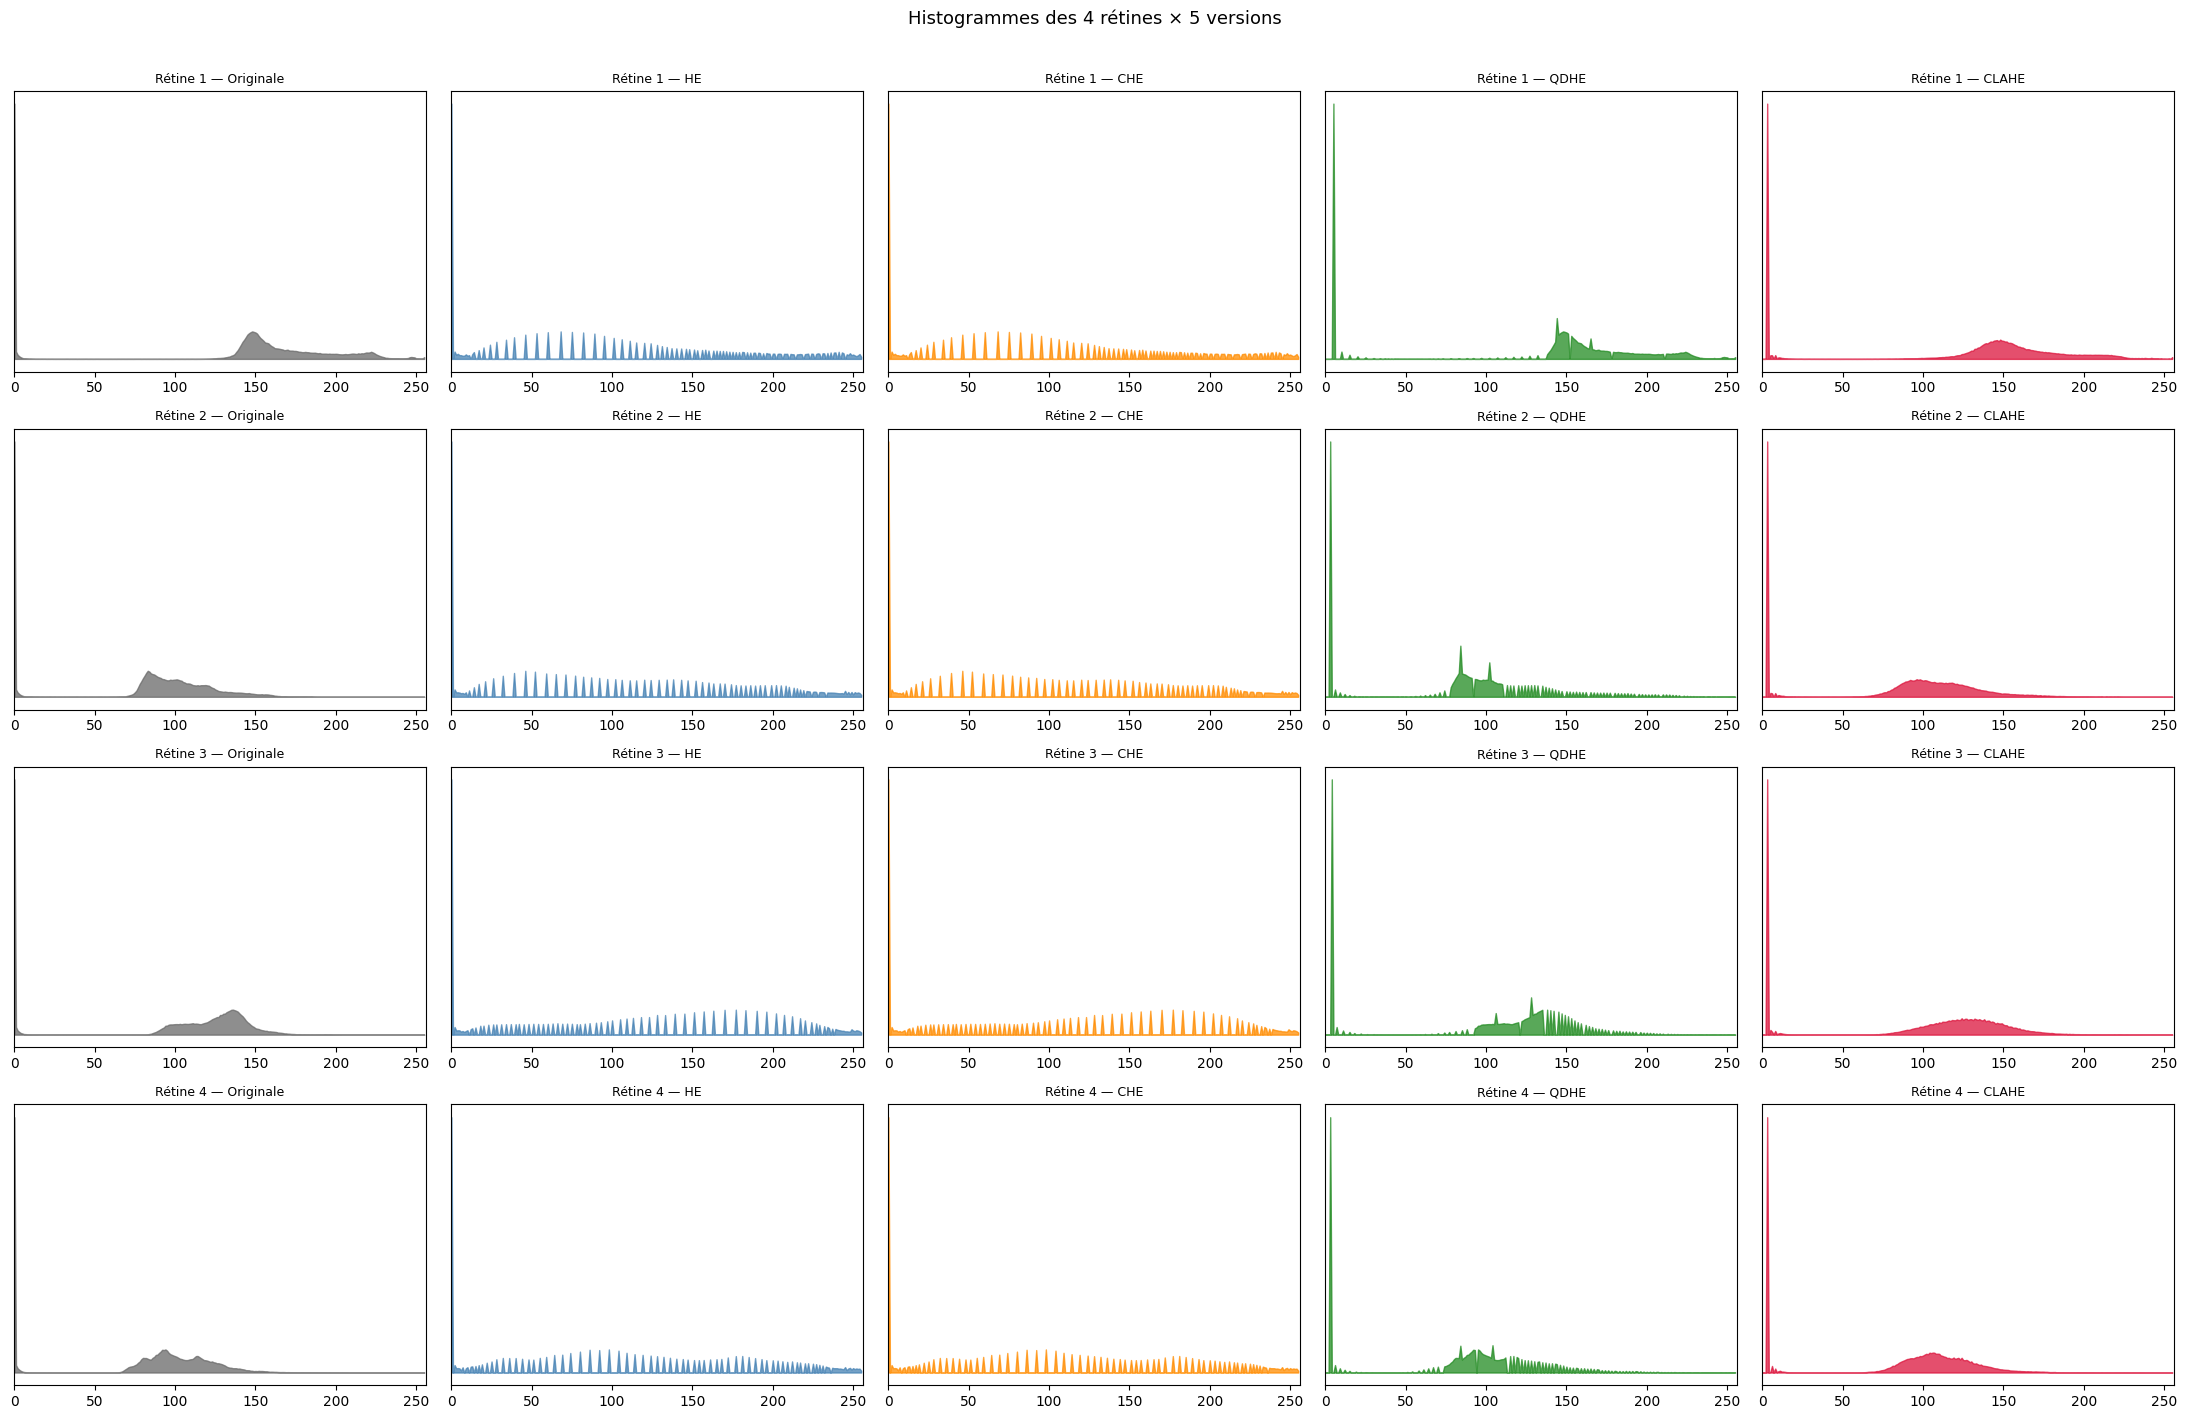

In [37]:
colors_hist = ["dimgray", "steelblue", "darkorange", "forestgreen", "crimson"]
col_titles  = ["Originale"] + method_names

fig, axes = plt.subplots(4, 5, figsize=(22, 14))

for row, (img, res, rname) in enumerate(zip(retinas, results_imgs, retina_names)):
    all_imgs = [img] + [res[m] for m in method_names]
    for col, (im, title, color) in enumerate(zip(all_imgs, col_titles, colors_hist)):
        h, _ = np.histogram(im.flatten(), 256, [0, 256])
        axes[row, col].fill_between(range(256), h, alpha=0.75, color=color)
        axes[row, col].set_xlim([0, 256])
        axes[row, col].set_title(f"{rname} — {title}", fontsize=9)
        axes[row, col].set_yticks([])

plt.suptitle("Histogrammes des 4 rétines × 5 versions", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Observation:**

L'analyse des histogrammes montre que les méthodes d'égalisation modifient la distribution des niveaux de gris de manière significative. HE tend à étaler les pixels sur une gamme plus large, tandis que CHE et QDHE peuvent créer des pics dans l'histogramme en fonction de la répartition des pixels dans les quadrants. CLAHE, en limitant le contraste local, produit souvent un histogramme plus équilibré sans pics extrêmes, ce qui peut être bénéfique pour préserver les détails dans les images de la rétine.

#### **IV. Evaluation des résultats des méthodes d'égalisation selon les métriques (MSE, PSNR, SD)**

$$\text{MSE} = \frac{1}{MN}\sum(I'-I)^2 \qquad \text{PSNR} = 10\log_{10}\frac{255^2}{\text{MSE}} \qquad \text{SD} = \sqrt{\frac{1}{n}\sum(f_{ij}-\bar{X})^2}$$

In [39]:
def compute_metrics(original, enhanced, L=256):
    orig = original.astype(np.float64)
    enh  = enhanced.astype(np.float64)
    mse  = np.mean((enh - orig) ** 2)
    psnr = 10 * np.log10((L - 1) ** 2 / mse) if mse > 0 else float('inf')
    sd   = enh.std()
    return mse, psnr, sd

**1. Tableau des métriques (MSE, PSNR, SD) pour les 4 méthodes d'égalisation appliquées aux 4 images de la rétine :**

In [43]:
rows = []
for img, res, rname in zip(retinas, results_imgs, retina_names):
    sd_orig = img.astype(np.float64).std()
    rows.append({"Image": rname, "Méthode": "Originale",
                 "MSE": 0.0, "PSNR (dB)": float('inf'), "SD": sd_orig})
    for mname in method_names:
        mse, psnr, sd = compute_metrics(img, res[mname])
        rows.append({"Image": rname, "Méthode": mname,
                     "MSE": mse, "PSNR (dB)": psnr, "SD": sd})

df = pd.DataFrame(rows)

**2. Affichage du tableau des métriques :**

In [44]:
df_display = df.copy()
df_display["MSE"]      = df_display["MSE"].map(lambda x: f"{x:.2f}")
df_display["PSNR (dB)"] = df_display["PSNR (dB)"].map(lambda x: "∞" if x == float('inf') else f"{x:.4f}")
df_display["SD"]       = df_display["SD"].map(lambda x: f"{x:.4f}")
print(df_display.to_string(index=False))

   Image   Méthode     MSE PSNR (dB)      SD
Rétine 1 Originale    0.00         ∞ 75.5571
Rétine 1        HE 2738.11   13.7563 83.5541
Rétine 1       CHE 2738.11   13.7563 83.5541
Rétine 1      QDHE   23.35   34.4471 73.8474
Rétine 1     CLAHE  228.71   24.5379 70.6415
Rétine 2 Originale    0.00         ∞ 47.2913
Rétine 2        HE 2682.32   13.8457 83.7002
Rétine 2       CHE 2682.32   13.8457 83.7002
Rétine 2      QDHE  201.99   25.0774 54.3541
Rétine 2     CLAHE  139.89   26.6730 50.4344
Rétine 3 Originale    0.00         ∞ 55.5893
Rétine 3        HE 2268.62   14.5732 84.2502
Rétine 3       CHE 2268.62   14.5732 84.2502
Rétine 3      QDHE   86.19   28.7761 57.9681
Rétine 3     CLAHE  123.27   27.2221 56.8060
Rétine 4 Originale    0.00         ∞ 47.4429
Rétine 4        HE 2685.45   13.8406 83.8864
Rétine 4       CHE 2685.45   13.8406 83.8864
Rétine 4      QDHE   92.31   28.4784 51.4272
Rétine 4     CLAHE  110.68   27.6903 49.6678


**3. Visualisation des métriques (MSE, PSNR, SD):**

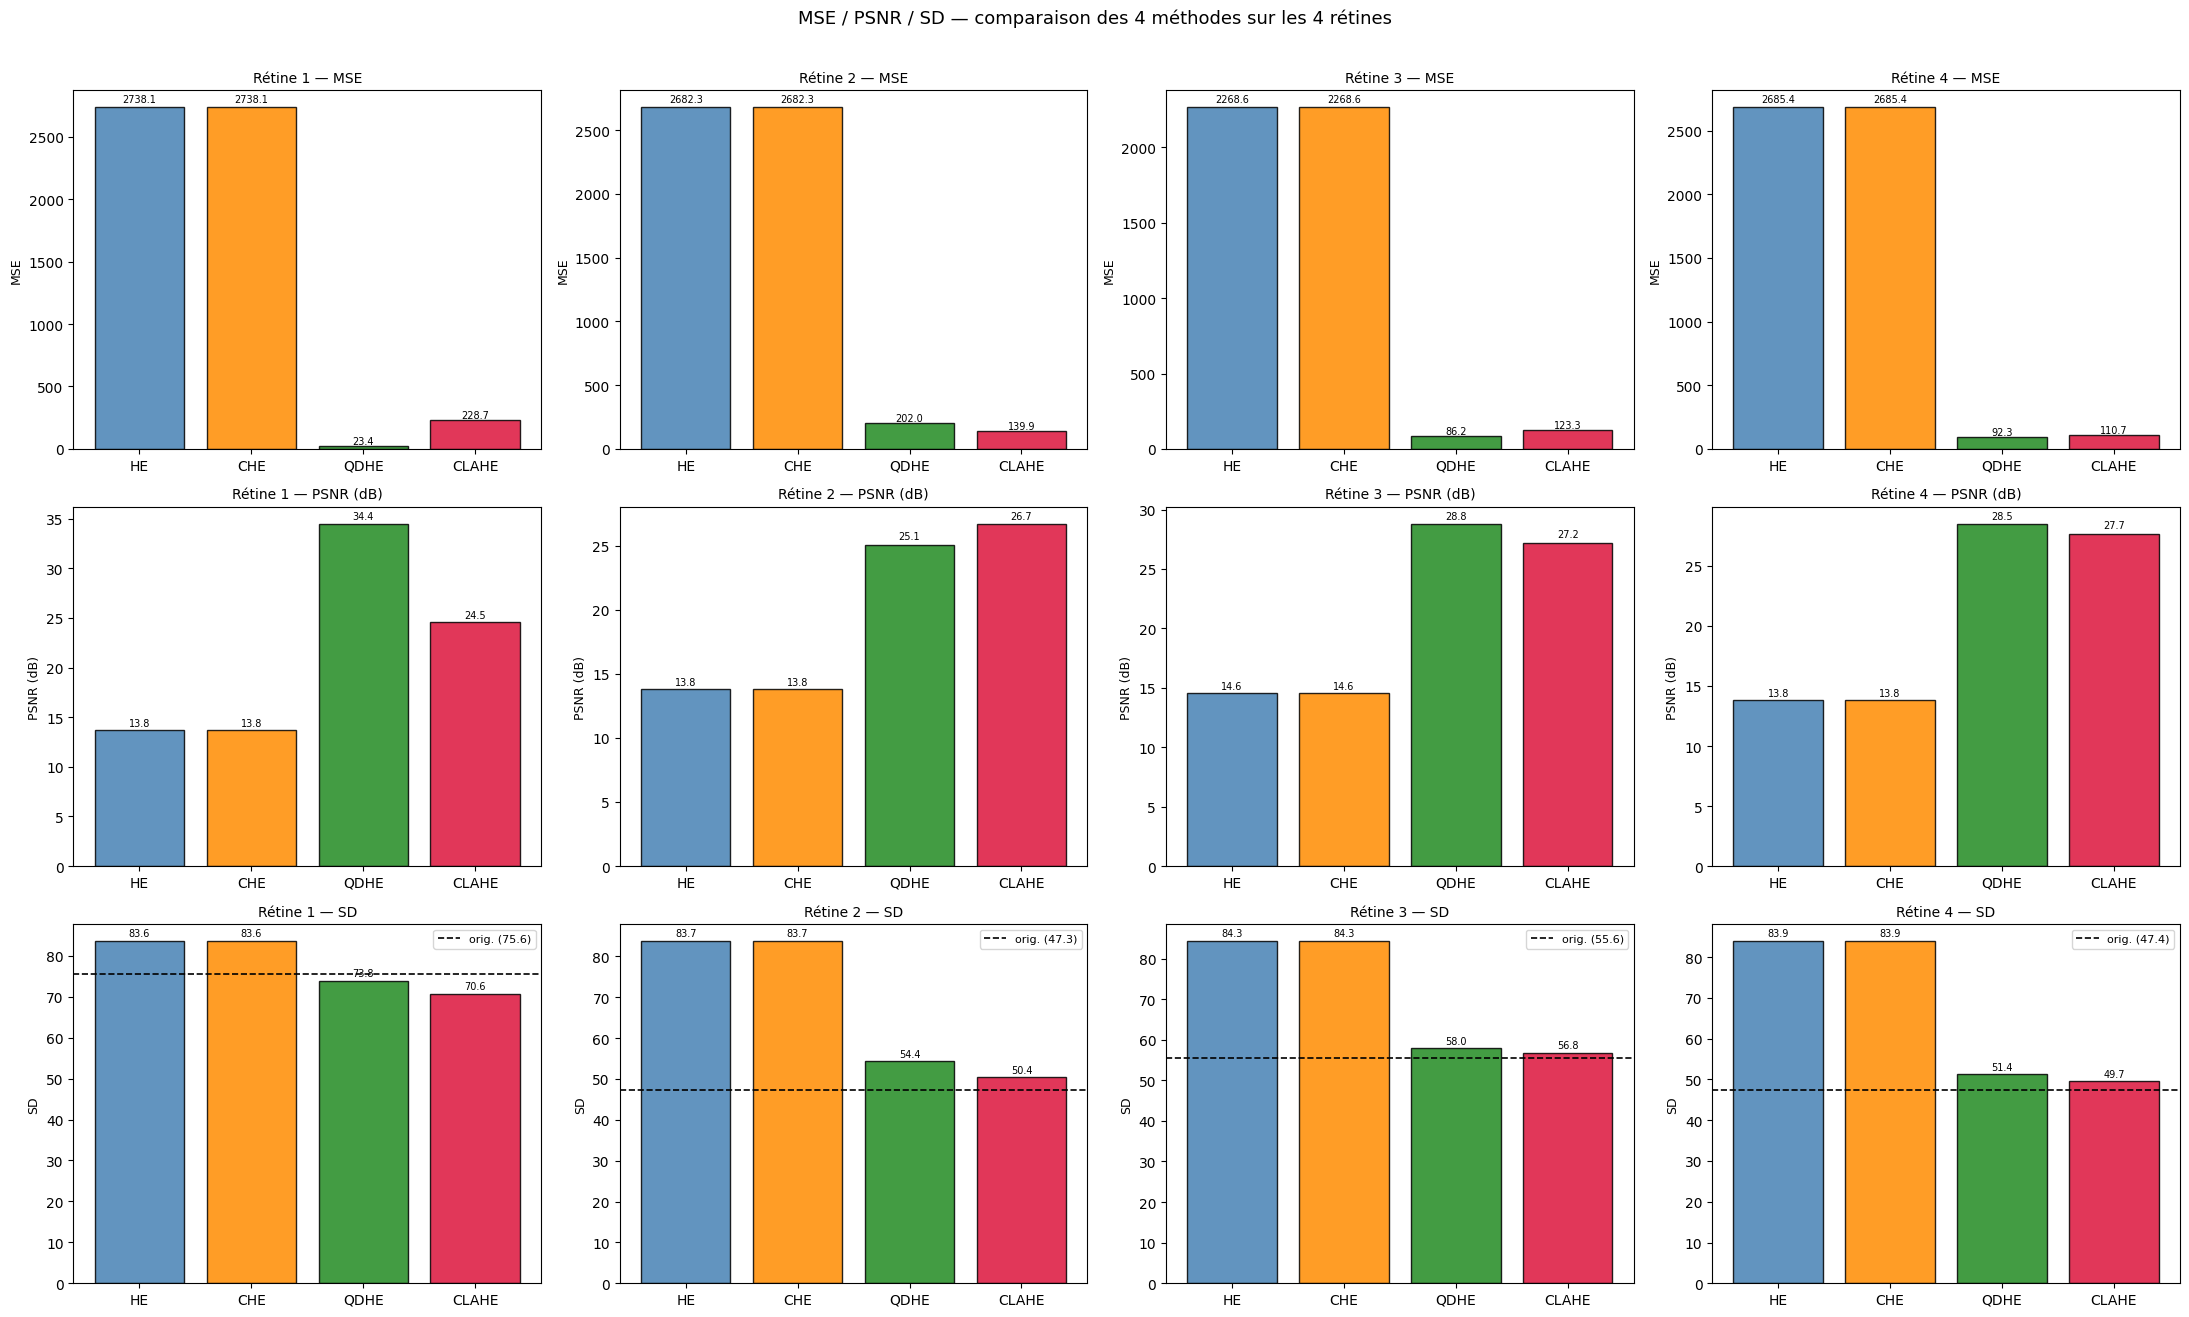

In [45]:
bar_colors  = ["steelblue", "darkorange", "forestgreen", "crimson"]
metric_list = ["MSE", "PSNR (dB)", "SD"]

fig, axes = plt.subplots(3, 4, figsize=(22, 13))

for row, metric in enumerate(metric_list):
    for col, rname in enumerate(retina_names):
        sub = df[(df["Image"] == rname) & (df["Méthode"] != "Originale")]
        vals = sub[metric].values
        bars = axes[row, col].bar(method_names, vals,
                                  color=bar_colors, edgecolor="black", alpha=0.85)
        axes[row, col].set_title(f"{rname} — {metric}", fontsize=10)
        axes[row, col].set_ylabel(metric, fontsize=9)

        # Valeur SD originale en tirets
        if metric == "SD":
            sd_orig = df[(df["Image"] == rname) & (df["Méthode"] == "Originale")]["SD"].values[0]
            axes[row, col].axhline(sd_orig, color="black", linestyle="--",
                                   linewidth=1.2, label=f"orig. ({sd_orig:.1f})")
            axes[row, col].legend(fontsize=8)

        # Valeurs sur barres
        for bar, val in zip(bars, vals):
            axes[row, col].text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() * 1.01,
                f"{val:.1f}", ha="center", va="bottom", fontsize=7)

plt.suptitle("MSE / PSNR / SD — comparaison des 4 méthodes sur les 4 rétines",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

#### **V. Conclusion:**

Les métriques MSE, PSNR et SD fournissent des indications complémentaires sur la qualité de l'amélioration du contraste. MSE et PSNR mesurent la fidélité par rapport à l'image originale, tandis que SD évalue la dispersion des niveaux de gris dans l'image améliorée. En général, une méthode d'égalisation qui améliore le contraste tout en préservant les détails (comme CLAHE) tend à avoir un MSE plus faible, un PSNR plus élevé et une SD plus proche de celle de l'image originale.

> **HE / CHE** redistribuent globalement → forte distorsion (MSE élevé, PSNR faible).
> **QDHE** préserve la luminosité par partition en quadrants → moins d'artefacts.
> **CLAHE** est le meilleur compromis sur les images de rétine grâce au clip limit.

Ces résultats sont cohérents avec les conclusions de **Salem et al. (2019)** : CLAHE est recommandé pour les images de rétine, QDHE pour les autres types d'images médicales (cerveau, genou, sein, endomètre).